# Trial-mode entropy vs LD1: robustness to the number of modes (supplementary)

`fig_engagement_syllables` panel G: mode-use entropy falls along LD1 (mouse level). How many modes the trials are cut into is the main free choice behind it, so the same entropy–LD1 test is repeated with the number of modes varied three independent ways, on the **same trials**:

1. **Merging the paper's modes** along the map's own density hierarchy (neighbouring basins merge in order of how shallow the valley between them is, as panel D's dendrogram), from 17 modes down to 2 — nested coarsenings of the paper's partition.
2. **Re-cutting the paper's map**: the watershed of the same UMAP density with other peak spacings (`min_distance`) and thresholds, which gives more or fewer basins.
3. **No UMAP at all**: k-means on the encoded trials themselves (360 binary features: paw one-hot, whisking, licking per bin), k from 4 to 40.

Plus one **UMAP refit** with the paper's settings and seed on this machine (`3_trial_modes/mode_entropy_robustness.py`): UMAP is not bit-reproducible across platforms, and this one gives 14 modes (adjusted Rand index 0.67 with the paper's) — a check of the embedding itself. The script can also run a UMAP n_neighbors × min_dist grid (~2 min per embedding); not used here.

Entropy estimator as panel G: per session, Shannon entropy of mode use over `N_SUB` subsamples of the shortest session's (labelled) trial count, normalised by log(number of modes); mice = mean over sessions; Spearman with mouse-mean LD1. Agreement with the paper's partition: adjusted Rand index (ARI) over trials both assign.

**LD1's sign** is as in the paper's LDA file, where the switchy end is the low end: a negative ρ is the paper's result.

In [1]:
import sys, pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.metrics import adjusted_rand_score
from datetime import date

FIGDIR = pathlib.Path.cwd().resolve()
while not (FIGDIR / 'fig_layout.py').exists() and FIGDIR != FIGDIR.parent:
    FIGDIR = FIGDIR / 'figure_generation' if (FIGDIR / 'figure_generation').exists() else FIGDIR.parent
PI = FIGDIR.parent
for p in [str(PI.parent), str(PI), str(FIGDIR)]:
    if p not in sys.path:
        sys.path.insert(0, p)
from Functions import trial_modes as tm
import paper_style as ps
import fig_layout as fl
ps.use('paper')
FIG = 'fig_mode_entropy_robustness'

FIT_DIR = PI / '3_trial_modes' / 'trial_modes_8_k_10_bin_syllables_02-10-2026'   # the paper's modes
ROB = PI / 'data' / 'mode_robustness'
LDA_FILE = PI / 'clustering' / 'data_files' / 'mouse_LDA_5_bins_raw_shrink0.5_wmouse_360_02-10-2026'
N_SUB = 100                         # subsamples per session (panel G uses 200; the estimate is stable well below)
WATERSHED_GRID = [(t, m) for t in (50, 60, 70) for m in (3, 5, 7, 10, 14, 20, 30)]   # (threshold_pct, min_distance)
PAPER_WS = (60, 10)
SEED = 0

paper_style: paper mode, spines=lb, font 8 pt, panels 3.4x2.4 in, save 400 dpi


## Partitions

In [2]:
import pickle
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform

trials = pd.read_parquet(FIT_DIR / 'trials.pqt')
valid = np.load(ROB / 'valid.npy')
tv = trials[valid].reset_index(drop=True)
lda = pd.read_pickle(LDA_FILE).rename(columns={0: 'LD1'})
in_lda = tv['session'].isin(lda['session']).to_numpy()
with open(FIT_DIR / 'fit.pkl', 'rb') as f:
    fit = pickle.load(f)
paper = tv['trial_cluster'].to_numpy()
PARTS = {('paper', 'paper', None): paper}

# 1. merge the paper's basins along the density hierarchy (as fig_engagement_syllables: barrier = relative dip at
#    the saddle between two basins, single linkage)
def basin_barriers(Z, labels, ids):
    peak = {k: Z[labels == k].max() for k in ids}
    sad = {}
    for la, lb, za, zb in [(labels[:-1], labels[1:], Z[:-1], Z[1:]), (labels[:, :-1], labels[:, 1:], Z[:, :-1], Z[:, 1:])]:
        m = (la > 0) & (lb > 0) & (la != lb)
        for x, y, v in zip(la[m], lb[m], np.minimum(za[m], zb[m])):
            key = (min(x, y), max(x, y)); sad[key] = max(sad.get(key, 0.0), v)
    D = np.ones((len(ids), len(ids))); np.fill_diagonal(D, 0)
    for (x, y), v in sad.items():
        i, j = ids.index(x), ids.index(y); D[i, j] = D[j, i] = 1 - v / min(peak[x], peak[y])
    return D
IDS = [int(k) for k in sorted(np.unique(paper[~np.isnan(paper)]))]
TREE = linkage(squareform(basin_barriers(fit['Z'], fit['labels'], IDS), checks=False), 'single')
for k in range(2, len(IDS)):
    grp = dict(zip(IDS, fcluster(TREE, k, criterion='maxclust')))
    PARTS[('merged', f'merged to {k}', None)] = np.array([grp[int(x)] if x == x else np.nan for x in paper], float)

# 2. re-cut the paper's own density map
emb = tv[['embedding_x', 'embedding_y']].to_numpy()
for ws in WATERSHED_GRID:
    PARTS[('watershed', f'watershed {ws}', ws)] = tm.assign(emb, tm.watershed_map(fit['Z'], *ws), fit['bounds'])

# 3. k-means, no UMAP
for f in sorted(ROB.glob('kmeans_k*.npy'), key=lambda f: int(f.stem[8:])):
    PARTS[('kmeans', f'k-means k = {int(f.stem[8:])}', None)] = np.load(f).astype(float)

# UMAP refit(s) on this machine, cut with the paper's watershed settings
for f in sorted(ROB.glob('umap_*.npy')):
    e = np.load(f); Z, b = tm.density_map(e)
    PARTS[('umap_refit', f'UMAP refit {f.stem[5:]}', PAPER_WS)] = tm.assign(e, tm.watershed_map(Z, *PAPER_WS), b)
print(f'{len(PARTS)} partitions of {len(tv):,} trials ({in_lda.sum():,} in the {lda["session"].nunique()} LDA sessions)')

49 partitions of 199,328 trials (158,564 in the 260 LDA sessions)


## Entropy vs LD1, per partition

In [3]:
def H(c):
    p = c[c > 0] / c.sum()
    return -(p * np.log(p)).sum()

sess = tv.loc[in_lda, 'session'].to_numpy()
LD1_MOUSE = lda.groupby('mouse_name')['LD1'].mean()
MOUSE_OF = lda.drop_duplicates('session').set_index('session')['mouse_name']
paper_lab = PARTS[list(PARTS)[0]]
rng = np.random.default_rng(SEED)
rows = []
for key, lab in PARTS.items():
    lab_l = lab[in_lda]
    ok = ~np.isnan(lab_l)
    codes, lab_i = np.unique(lab_l[ok], return_inverse=True)
    K = len(codes)
    s_ok = pd.Series(lab_i, index=sess[ok])
    n_min = s_ok.groupby(level=0).size().min()
    ent = {}
    for s, v in s_ok.groupby(level=0):
        v = v.to_numpy()
        ent[s] = np.mean([H(np.bincount(rng.choice(v, n_min, replace=False), minlength=K)) for _ in range(N_SUB)]) / np.log(K)
    m = pd.Series(ent).groupby(MOUSE_OF).mean()
    r = spearmanr(LD1_MOUSE.reindex(m.index), m)
    both = ~np.isnan(lab) & ~np.isnan(paper_lab)
    rows.append(dict(method=key[0], setting=key[1], watershed=key[2], n_modes=K, unassigned=1 - ok.mean(),
                     n_min=n_min, rho=r.statistic, p=r.pvalue, ari=adjusted_rand_score(paper_lab[both], lab[both])))
R = pd.DataFrame(rows)
pd.set_option('display.width', 160)
print(R.round(3).to_string())

        method                    setting watershed  n_modes  unassigned  n_min    rho      p    ari
0        paper                      paper      None       17       0.020    372 -0.369  0.005  1.000
1       merged                merged to 2      None        2       0.020    372  0.514  0.000  0.011
2       merged                merged to 3      None        3       0.020    372  0.144  0.291  0.095
3       merged                merged to 4      None        4       0.020    372  0.146  0.284  0.101
4       merged                merged to 5      None        5       0.020    372  0.016  0.906  0.106
5       merged                merged to 6      None        6       0.020    372  0.093  0.493  0.303
6       merged                merged to 7      None        7       0.020    372 -0.041  0.764  0.350
7       merged                merged to 8      None        8       0.020    372  0.019  0.888  0.351
8       merged                merged to 9      None        9       0.020    372 -0.098  0.4

In [4]:
print(R.groupby('method')[['n_modes', 'rho', 'p']].agg(['min', 'max']).round(3))
print(f"\nall {len(R)} partitions: rho from {R['rho'].min():.2f} to {R['rho'].max():.2f}, "
      f"negative in {(R['rho'] < 0).mean():.0%}, p < 0.05 in {(R['p'] < 0.05).mean():.0%}")
for meth in ['merged', 'watershed', 'kmeans']:
    d = R[(R['method'] == meth) & (R['n_modes'] >= 5)]
    print(f'{meth:10s} with >= 5 modes: rho {d["rho"].min():.2f} to {d["rho"].max():.2f}, p < 0.05 in {(d["p"] < 0.05).mean():.0%} of {len(d)}')

           n_modes        rho             p       
               min max    min    max    min    max
method                                            
kmeans           4  40 -0.452  0.047  0.000  0.798
merged           2  16 -0.403  0.514  0.000  0.906
paper           17  17 -0.369 -0.369  0.005  0.005
umap_refit      14  14 -0.389 -0.389  0.003  0.003
watershed        4  18 -0.493  0.033  0.000  0.940

all 49 partitions: rho from -0.49 to 0.51, negative in 84%, p < 0.05 in 67%
merged     with >= 5 modes: rho -0.40 to 0.09, p < 0.05 in 33% of 12
watershed  with >= 5 modes: rho -0.42 to 0.03, p < 0.05 in 83% of 18
kmeans     with >= 5 modes: rho -0.45 to 0.05, p < 0.05 in 70% of 10


## The figure

**a** ρ (mouse level, mode entropy vs LD1) against the number of modes, for the three ways of varying it; filled = p < 0.05; the paper's partition (17 modes) as a black diamond, the UMAP refit as a black square. **b** how similar each partition is to the paper's (ARI), against the number of modes.

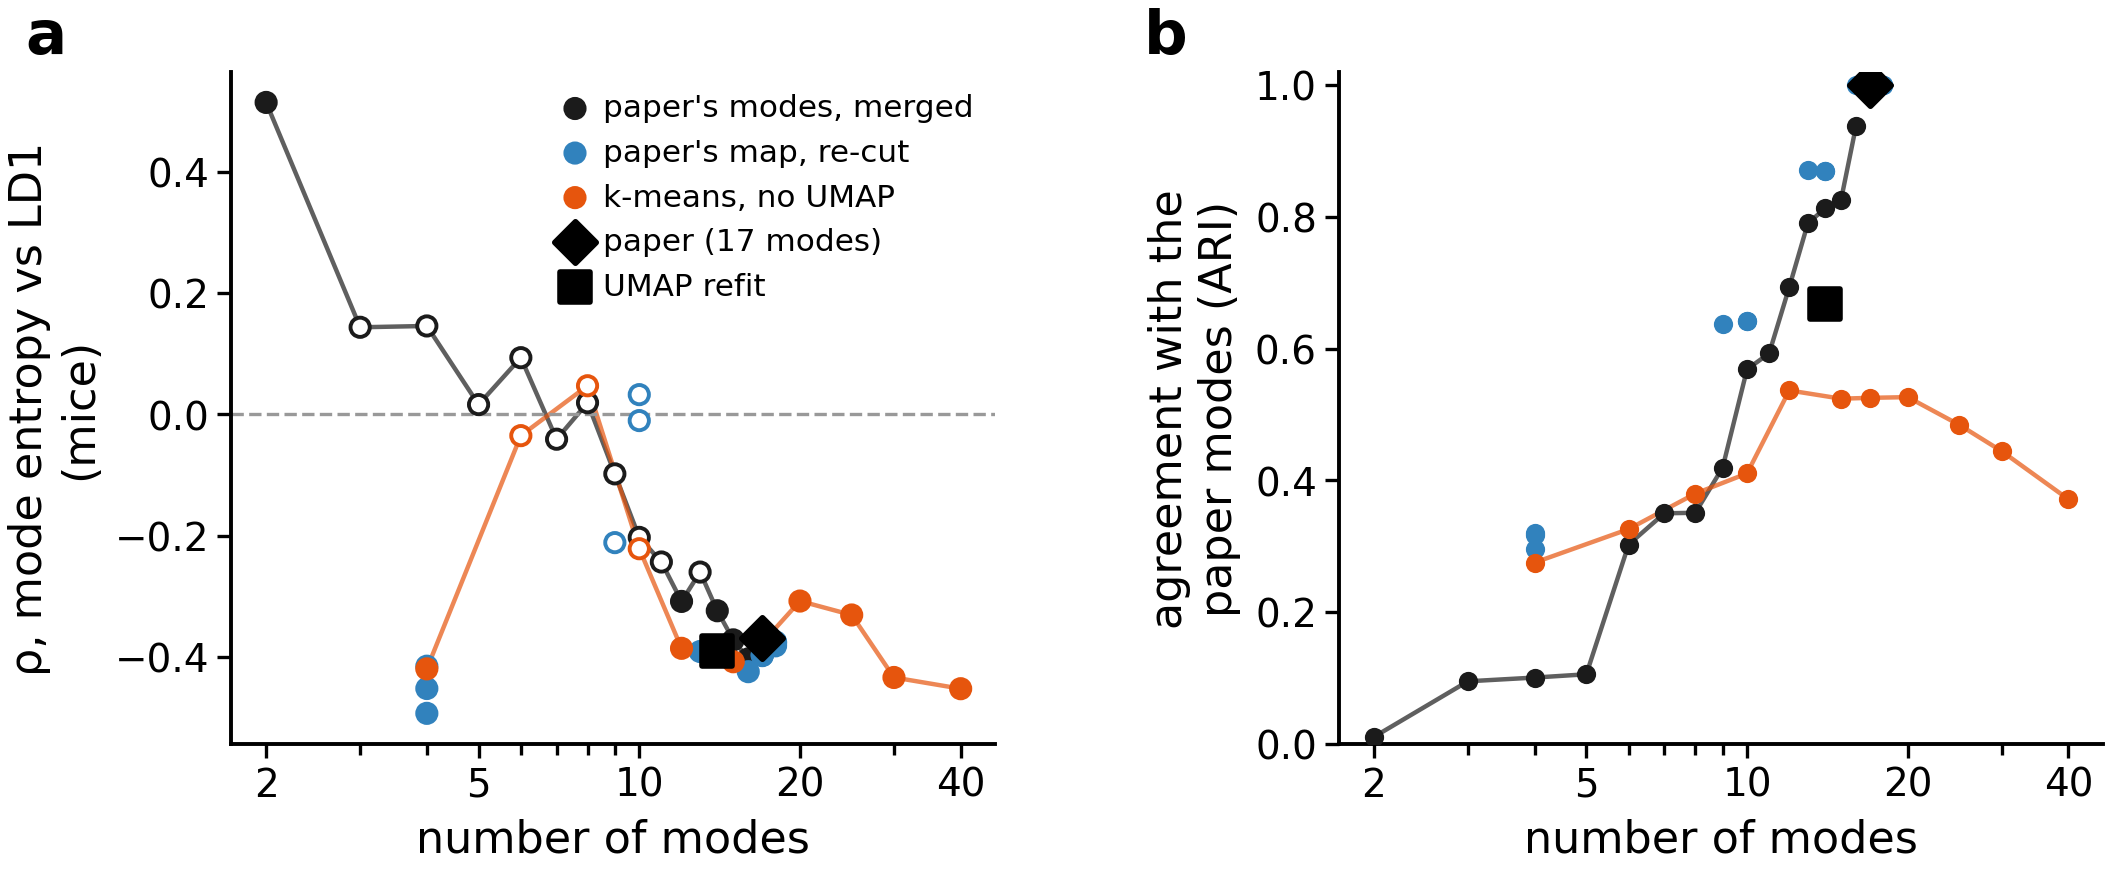

wrote figure_generation/figures/fig_mode_entropy_robustness_02-11-2026.svg


wrote figure_generation/figures/fig_mode_entropy_robustness.pdf
wrote figure_generation/figures/fig_mode_entropy_robustness.png


In [5]:
COL = {'merged': '#1b1b1b', 'watershed': '#3182bd', 'kmeans': '#e6550d'}
NAME = {'merged': "paper's modes, merged", 'watershed': "paper's map, re-cut", 'kmeans': 'k-means, no UMAP'}
fs = plt.rcParams['font.size']
fig = plt.figure(figsize=(fl.FIG_WIDTH * 0.75, 2.4))
g = fig.add_gridspec(1, 2, wspace=0.45, left=0.1, right=0.98, top=0.9, bottom=0.2)
axa, axb = fig.add_subplot(g[0]), fig.add_subplot(g[1])
for meth in ['merged', 'watershed', 'kmeans']:
    d = R[R['method'] == meth].sort_values('n_modes')
    if meth != 'watershed':
        axa.plot(d['n_modes'], d['rho'], color=COL[meth], lw=0.8, alpha=0.7)
        axb.plot(d['n_modes'], d['ari'], color=COL[meth], lw=0.8, alpha=0.7)
    axa.scatter(d['n_modes'], d['rho'], s=12, facecolor=np.where(d['p'] < 0.05, COL[meth], 'white'),
                edgecolor=COL[meth], lw=0.7, zorder=3, label=NAME[meth])
    axb.scatter(d['n_modes'], d['ari'], s=12, color=COL[meth], lw=0, zorder=3)
for meth, mk in [('paper', 'D'), ('umap_refit', 's')]:
    d = R[R['method'] == meth]
    axa.scatter(d['n_modes'], d['rho'], s=28, marker=mk, color='k', zorder=4,
                label={'paper': 'paper (17 modes)', 'umap_refit': 'UMAP refit'}[meth])
    axb.scatter(d['n_modes'], d['ari'], s=28, marker=mk, color='k', zorder=4)
axa.axhline(0, color='0.6', lw=0.6, ls='--')
axa.set_xlabel('number of modes'); axa.set_ylabel('ρ, mode entropy vs LD1\n(mice)')
axa.set_xscale('log'); axb.set_xscale('log')
for a in (axa, axb):
    a.set_xticks([2, 5, 10, 20, 40]); a.set_xticklabels([2, 5, 10, 20, 40])
axa.legend(frameon=False, fontsize=fs * 0.7, loc='upper right', handletextpad=0.2)
axb.set_xlabel('number of modes'); axb.set_ylabel('agreement with the\npaper modes (ARI)'); axb.set_ylim(0, 1.02)
fl.place_letters(fig, {'a': [axa], 'b': [axb]}, rows=['ab'], left='a')
plt.show()
OUT = FIGDIR / 'figures'
for path in [OUT / f"{FIG}_{date.today().strftime('%d-%m-%Y')}.svg", OUT / f'{FIG}.pdf', OUT / f'{FIG}.png']:
    fig.savefig(path, dpi=300)
    print('wrote', path.relative_to(PI))